In [2]:
%pip install requests beautifulsoup4 pandas networkx matplotlib pyvis

   ---------------------------------------- 0.0/756.0 kB ? eta -:--:--
   ---------------------------------------- 0.0/756.0 kB ? eta -:--:--
   ---------------------------------------- 0.0/756.0 kB ? eta -:--:--
   ------------- -------------------------- 262.1/756.0 kB ? eta -:--:--
   ------------- -------------------------- 262.1/756.0 kB ? eta -:--:--
   -------------------------- ----------- 524.3/756.0 kB 535.5 kB/s eta 0:00:01
   -------------------------- ----------- 524.3/756.0 kB 535.5 kB/s eta 0:00:01
   ---------------------------------------- 756.0/756.0 kB 559.3 kB/s  0:00:01

   ---------------------------------------- 0/2 [jsonpickle]
   ---------------------------------------- 0/2 [jsonpickle]
   -------------------- ------------------- 1/2 [pyvis]
   -------------------- ------------------- 1/2 [pyvis]
   ---------------------------------------- 2/2 [pyvis]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# Import Library

In [3]:
# Import library untuk Web Crawling
import requests
from bs4 import BeautifulSoup
from urllib.parse import urljoin, urlparse
from urllib.robotparser import RobotFileParser
import time

# Import library untuk pengolahan data
import pandas as pd
from collections import deque

# Import library untuk Graph dan PageRank
import networkx as nx
import matplotlib.pyplot as plt

# Import library untuk visualisasi interaktif
from pyvis.network import Network

print("Semua library berhasil diimport!")

Semua library berhasil diimport!


# Fungsi untuk Mengambil URL Website

In [5]:
# Fungsi untuk mengambil URL dari halaman website
def ekstraksi_url(url):
    daftar_url = set()

    try:
        # Mengakses halaman website
        response = requests.get(
            url,
            timeout=10,
            headers={"User-Agent": "PPWPageRankBot/1.0"}
        )
        response.raise_for_status()

        # Memproses konten HTML
        soup = BeautifulSoup(response.text, "html.parser")

        # Mengambil semua tag <a> yang memiliki href
        for link in soup.find_all("a", href=True):

            # Mengubah URL relatif menjadi URL absolut
            url_lengkap = urljoin(url, link["href"])

            # Menghapus fragment URL (#)
            url_lengkap = url_lengkap.split("#")[0]

            # Memastikan URL menggunakan HTTP atau HTTPS
            if urlparse(url_lengkap).scheme in ["http", "https"]:
                daftar_url.add(url_lengkap)

    except requests.RequestException as e:
        print(f"Gagal mengakses {url}: {e}")

    return sorted(daftar_url)


# Website awal yang akan diuji
url_awal = "https://quotes.toscrape.com/"

# Menjalankan fungsi ekstraksi URL
hasil_url = ekstraksi_url(url_awal)

# Menampilkan hasil
print("Jumlah URL ditemukan:", len(hasil_url))

for nomor, url in enumerate(hasil_url, start=1):
    print(f"{nomor}. {url}")

Jumlah URL ditemukan: 49
1. https://quotes.toscrape.com/
2. https://quotes.toscrape.com/author/Albert-Einstein
3. https://quotes.toscrape.com/author/Andre-Gide
4. https://quotes.toscrape.com/author/Eleanor-Roosevelt
5. https://quotes.toscrape.com/author/J-K-Rowling
6. https://quotes.toscrape.com/author/Jane-Austen
7. https://quotes.toscrape.com/author/Marilyn-Monroe
8. https://quotes.toscrape.com/author/Steve-Martin
9. https://quotes.toscrape.com/author/Thomas-A-Edison
10. https://quotes.toscrape.com/login
11. https://quotes.toscrape.com/page/2/
12. https://quotes.toscrape.com/tag/abilities/page/1/
13. https://quotes.toscrape.com/tag/adulthood/page/1/
14. https://quotes.toscrape.com/tag/aliteracy/page/1/
15. https://quotes.toscrape.com/tag/be-yourself/page/1/
16. https://quotes.toscrape.com/tag/books/
17. https://quotes.toscrape.com/tag/books/page/1/
18. https://quotes.toscrape.com/tag/change/page/1/
19. https://quotes.toscrape.com/tag/choices/page/1/
20. https://quotes.toscrape.com/ta

In [6]:
# Fungsi untuk melakukan Web Crawling secara berulang
def web_crawling(url_awal, max_halaman=20, max_depth=2):

    # Menyimpan URL yang sudah dikunjungi
    visited = set()

    # Menyimpan hubungan antarhalaman
    edges = set()

    # Antrean URL beserta kedalamannya
    queue = deque([(url_awal, 0)])

    # Membatasi crawling pada domain yang sama
    domain_awal = urlparse(url_awal).netloc

    # Membaca aturan robots.txt
    robots = RobotFileParser()
    robots.set_url(urljoin(url_awal, "/robots.txt"))

    user_agent = "PPWPageRankBot/1.0"

    try:
        robots.read()
    except Exception as e:
        print(f"Gagal membaca robots.txt: {e}")
        return visited, edges

    while queue and len(visited) < max_halaman:

        # Mengambil URL dari antrean
        url, depth = queue.popleft()

        # Melewati URL yang sudah dikunjungi
        if url in visited:
            continue

        # Membatasi domain
        if urlparse(url).netloc != domain_awal:
            continue

        # Memeriksa izin crawling
        if not robots.can_fetch(user_agent, url):
            print(f"Tidak diizinkan: {url}")
            continue

        print(f"Crawling: {url} | Depth: {depth}")

        # Mengambil tautan dari halaman
        daftar_url = ekstraksi_url(url)

        # Menandai halaman sudah dikunjungi
        visited.add(url)

        for link in daftar_url:

            # Hanya mengambil URL dari domain yang sama
            if urlparse(link).netloc == domain_awal:

                # Menyimpan hubungan URL
                edges.add((url, link))

                # Menambahkan URL baru ke antrean
                if depth < max_depth and link not in visited:
                    queue.append((link, depth + 1))

        # Memberikan jeda agar tidak membebani server
        time.sleep(1)

    return visited, edges


# Menjalankan Web Crawling
url_awal = "https://quotes.toscrape.com/"

visited, edges = web_crawling(
    url_awal,
    max_halaman=20,
    max_depth=2
)

# Menampilkan hasil crawling
print("\nJumlah halaman dikunjungi:", len(visited))
print("Jumlah hubungan URL:", len(edges))

Crawling: https://quotes.toscrape.com/ | Depth: 0
Crawling: https://quotes.toscrape.com/author/Albert-Einstein | Depth: 1
Crawling: https://quotes.toscrape.com/author/Andre-Gide | Depth: 1
Crawling: https://quotes.toscrape.com/author/Eleanor-Roosevelt | Depth: 1
Crawling: https://quotes.toscrape.com/author/J-K-Rowling | Depth: 1
Crawling: https://quotes.toscrape.com/author/Jane-Austen | Depth: 1
Crawling: https://quotes.toscrape.com/author/Marilyn-Monroe | Depth: 1
Crawling: https://quotes.toscrape.com/author/Steve-Martin | Depth: 1
Crawling: https://quotes.toscrape.com/author/Thomas-A-Edison | Depth: 1
Crawling: https://quotes.toscrape.com/login | Depth: 1
Crawling: https://quotes.toscrape.com/page/2/ | Depth: 1
Crawling: https://quotes.toscrape.com/tag/abilities/page/1/ | Depth: 1
Crawling: https://quotes.toscrape.com/tag/adulthood/page/1/ | Depth: 1
Crawling: https://quotes.toscrape.com/tag/aliteracy/page/1/ | Depth: 1
Crawling: https://quotes.toscrape.com/tag/be-yourself/page/1/ | 

In [7]:
# Mengubah hasil crawling menjadi DataFrame
df_crawling = pd.DataFrame(
    sorted(edges),
    columns=["Source", "Target"]
)

# Menambahkan nomor urut mulai dari 1
df_crawling.index = range(1, len(df_crawling) + 1)

# Menampilkan jumlah data
print("Jumlah hubungan URL:", len(df_crawling))

# Menampilkan 10 data pertama
display(df_crawling.head(10))

Jumlah hubungan URL: 317


,Source,Target
1,https://quotes.toscrape.com/,https://quotes.toscrape.com/
2,https://quotes.toscrape.com/,https://quotes.toscrape.com/author/Albert-Eins...
3,https://quotes.toscrape.com/,https://quotes.toscrape.com/author/Andre-Gide
4,https://quotes.toscrape.com/,https://quotes.toscrape.com/author/Eleanor-Roo...
5,https://quotes.toscrape.com/,https://quotes.toscrape.com/author/J-K-Rowling
6,https://quotes.toscrape.com/,https://quotes.toscrape.com/author/Jane-Austen
7,https://quotes.toscrape.com/,https://quotes.toscrape.com/author/Marilyn-Monroe
8,https://quotes.toscrape.com/,https://quotes.toscrape.com/author/Steve-Martin
9,https://quotes.toscrape.com/,https://quotes.toscrape.com/author/Thomas-A-Ed...
10,https://quotes.toscrape.com/,https://quotes.toscrape.com/login


In [8]:
# Membuat graph berarah
G = nx.DiGraph()

# Menambahkan halaman yang berhasil dikunjungi sebagai node
G.add_nodes_from(visited)

# Menambahkan hubungan URL sebagai edge
for source, target in edges:
    G.add_edge(source, target)

# Menampilkan informasi graph
print("Jumlah Node:", G.number_of_nodes())
print("Jumlah Edge:", G.number_of_edges())
print("Jenis Graph:", type(G).__name__)

# Menampilkan daftar node
print("\nDaftar Node:")
for nomor, node in enumerate(G.nodes(), start=1):
    print(f"{nomor}. {node}")

# Menampilkan daftar edge
print("\nDaftar Edge:")
for nomor, (source, target) in enumerate(G.edges(), start=1):
    print(f"{nomor}. {source} -> {target}")

Jumlah Node: 100
Jumlah Edge: 317
Jenis Graph: DiGraph

Daftar Node:
1. https://quotes.toscrape.com/author/Andre-Gide
2. https://quotes.toscrape.com/author/J-K-Rowling
3. https://quotes.toscrape.com/tag/change/page/1/
4. https://quotes.toscrape.com/tag/adulthood/page/1/
5. https://quotes.toscrape.com/tag/books/
6. https://quotes.toscrape.com/tag/classic/page/1/
7. https://quotes.toscrape.com/author/Thomas-A-Edison
8. https://quotes.toscrape.com/page/2/
9. https://quotes.toscrape.com/tag/choices/page/1/
10. https://quotes.toscrape.com/author/Steve-Martin
11. https://quotes.toscrape.com/author/Eleanor-Roosevelt
12. https://quotes.toscrape.com/login
13. https://quotes.toscrape.com/author/Albert-Einstein
14. https://quotes.toscrape.com/
15. https://quotes.toscrape.com/author/Jane-Austen
16. https://quotes.toscrape.com/tag/be-yourself/page/1/
17. https://quotes.toscrape.com/tag/abilities/page/1/
18. https://quotes.toscrape.com/tag/aliteracy/page/1/
19. https://quotes.toscrape.com/tag/books/

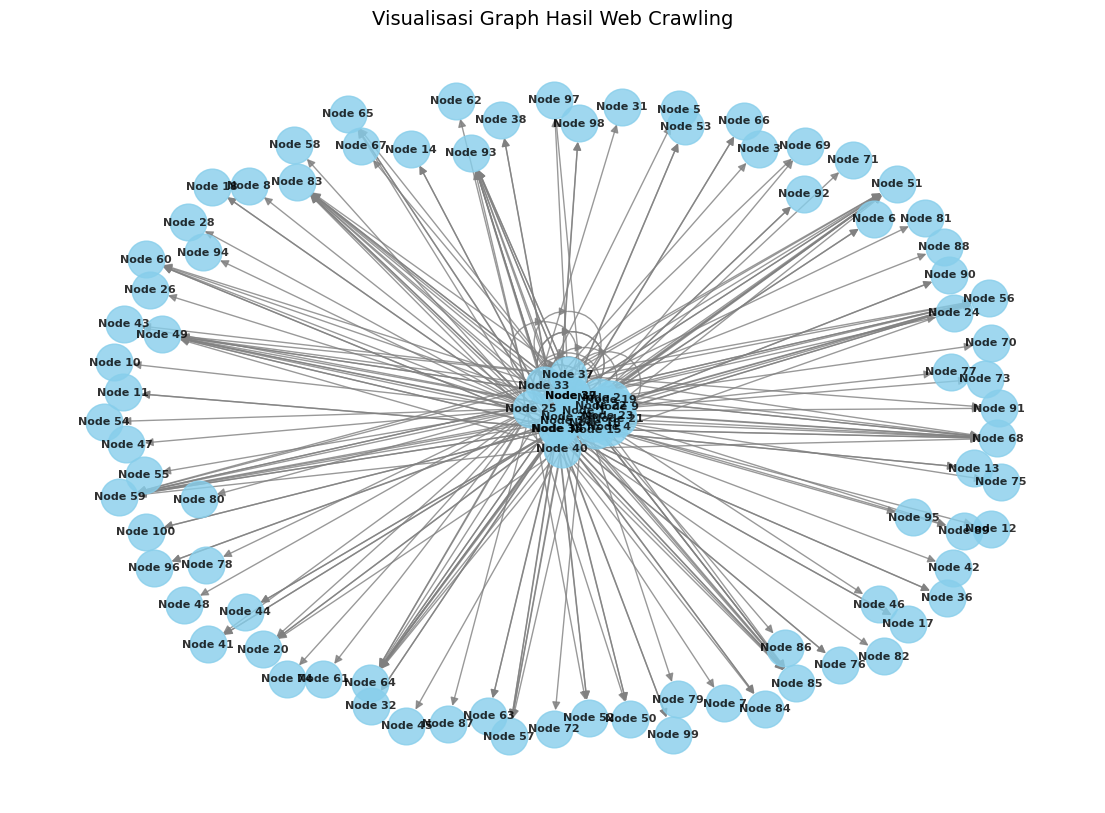

In [9]:
# Membuat ukuran visualisasi
plt.figure(figsize=(14, 10))

# Mengatur posisi node
pos = nx.spring_layout(G, seed=42)

# Membuat label node lebih singkat
label_node = {
    node: f"Node {i+1}"
    for i, node in enumerate(sorted(G.nodes()))
}

# Menggambar graph berarah
nx.draw_networkx(
    G,
    pos,
    labels=label_node,
    with_labels=True,
    node_size=700,
    node_color="skyblue",
    font_size=8,
    font_weight="bold",
    edge_color="gray",
    arrows=True,
    arrowsize=12,
    width=1,
    alpha=0.8
)

# Menambahkan judul
plt.title(
    "Visualisasi Graph Hasil Web Crawling",
    fontsize=14
)

# Menghilangkan sumbu
plt.axis("off")

# Menampilkan graph
plt.show()

# Menghitung PageRank Menggunakan NetworkX

In [10]:
# Menghitung PageRank pada graph
pagerank = nx.pagerank(G, alpha=0.85, max_iter=1000)

# Mengurutkan hasil PageRank dari tertinggi ke terendah
ranking_pagerank = sorted(
    pagerank.items(),
    key=lambda x: x[1],
    reverse=True
)

# Menampilkan hasil PageRank
print("HASIL PERHITUNGAN PAGERANK")
print("=" * 80)

for nomor, (url, skor) in enumerate(ranking_pagerank, start=1):
    print(f"{nomor}. {url}")
    print(f"   PageRank: {skor:.6f}")
    print("-" * 80)

# Menampilkan halaman dengan PageRank tertinggi
if ranking_pagerank:
    url_tertinggi, skor_tertinggi = ranking_pagerank[0]

    print("\nHALAMAN DENGAN PAGERANK TERTINGGI")
    print("URL:", url_tertinggi)
    print(f"Nilai PageRank: {skor_tertinggi:.6f}")

HASIL PERHITUNGAN PAGERANK
1. https://quotes.toscrape.com/login
   PageRank: 0.076345
--------------------------------------------------------------------------------
2. https://quotes.toscrape.com/
   PageRank: 0.076345
--------------------------------------------------------------------------------
3. https://quotes.toscrape.com/tag/books/
   PageRank: 0.012724
--------------------------------------------------------------------------------
4. https://quotes.toscrape.com/tag/reading/
   PageRank: 0.012724
--------------------------------------------------------------------------------
5. https://quotes.toscrape.com/tag/truth/
   PageRank: 0.012724
--------------------------------------------------------------------------------
6. https://quotes.toscrape.com/tag/humor/
   PageRank: 0.012724
--------------------------------------------------------------------------------
7. https://quotes.toscrape.com/tag/friendship/
   PageRank: 0.012724
-----------------------------------------------

# Membuat Tabel Ranking PageRank

In [11]:
# Membuat DataFrame hasil PageRank
df_pagerank = pd.DataFrame(
    ranking_pagerank,
    columns=["URL", "PageRank"]
)

# Menambahkan kolom ranking
df_pagerank.insert(
    0,
    "Ranking",
    range(1, len(df_pagerank) + 1)
)

# Membulatkan nilai PageRank
df_pagerank["PageRank"] = df_pagerank["PageRank"].round(6)

# Menampilkan 10 halaman dengan PageRank tertinggi
print("TOP 10 HALAMAN DENGAN PAGERANK TERTINGGI")
display(df_pagerank.head(10))

TOP 10 HALAMAN DENGAN PAGERANK TERTINGGI


,Ranking,URL,PageRank
0,1,https://quotes.toscrape.com/login,0.076345
1,2,https://quotes.toscrape.com/,0.076345
2,3,https://quotes.toscrape.com/tag/books/,0.012724
3,4,https://quotes.toscrape.com/tag/reading/,0.012724
4,5,https://quotes.toscrape.com/tag/truth/,0.012724
5,6,https://quotes.toscrape.com/tag/humor/,0.012724
6,7,https://quotes.toscrape.com/tag/friendship/,0.012724
7,8,https://quotes.toscrape.com/tag/inspirational/,0.012724
8,9,https://quotes.toscrape.com/tag/life/,0.012724
9,10,https://quotes.toscrape.com/tag/friends/,0.012724


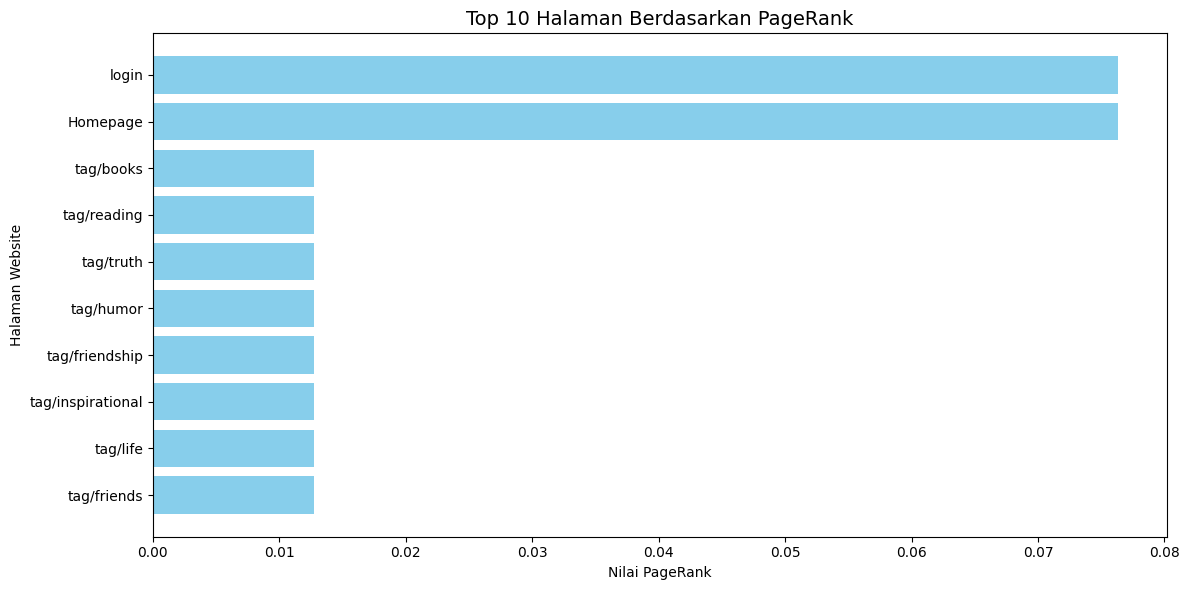

In [12]:
# Mengambil 10 halaman dengan PageRank tertinggi
top_10 = df_pagerank.head(10).copy()

# Membuat label URL lebih singkat
top_10["Label"] = top_10["URL"].apply(
    lambda url: urlparse(url).path.strip("/") or "Homepage"
)

# Membuat grafik batang horizontal
plt.figure(figsize=(12, 6))

plt.barh(
    top_10["Label"],
    top_10["PageRank"],
    color="skyblue"
)

# Membalik urutan agar ranking tertinggi berada di atas
plt.gca().invert_yaxis()

# Menambahkan judul dan label
plt.title("Top 10 Halaman Berdasarkan PageRank", fontsize=14)
plt.xlabel("Nilai PageRank")
plt.ylabel("Halaman Website")

# Merapikan tampilan
plt.tight_layout()

# Menampilkan grafik
plt.show()